# 04 — Medidas das 3 dimensões × idade da conta (por autor, dentro de cada ferramenta)

| RQ | Dimensão | Spec Kit | OpenSpec | Referências |
|---|---|---|---|---|
| RQ1 | Open items | % de specs com pendência (`n_needs_clarification`, `n_todo` ou `has_unfilled_placeholder`) | % média de tarefas não concluídas no `tasks.md` da mudança | Potdar & Shihab 2014; Maldonado & Shihab 2015 |
| RQ2 | Traceability | % de specs com PR vinculado (`n_linked_prs` > 0) | idem + % de referências a código que existem (`openspec_code_refs`) | Gotel & Finkelstein 1994; Cleland-Huang et al. 2012 |
| RQ3 | Scenario detail | mediana de passos Given/When/Then (`n_gherkin`) | mediana de cenários por requisito (`n_scenario_blocks / n_shall`) | Mavin et al. 2009; ISO/IEC/IEEE 29148; Femmer et al. 2017 |

Idade da conta: `data/autores_idade_v2.csv` (primeiro uso de SDD; negativos zerados). Filtros: specs em inglês, criador humano, `content_family` ∈ {openspec, speckit}.
Estatística: Spearman por autor, IC 95% por bootstrap, correção de Holm, e correlação parcial controlando o tamanho (`n_words`).
Rodar em ordem, de cima para baixo. Não precisa de token do GitHub.

In [26]:
# 1) Configuração
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Doutorado - PPGC/2026 2 - Tendências em Engenharia de Software/MSR'
DATA = os.path.join(BASE, 'data')
HF = 'https://huggingface.co/api/datasets/ShyAgarwal/specmine/parquet/{}/train/0.parquet'
def fonte(tabela):
    return HF.format(tabela)

MIN_SPECS = 1      # mínimo de specs por autor (ponto a validar)
N_BOOT = 1000      # reamostras do bootstrap
SEED = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
# 2) Carregar dados
sf = pd.read_parquet(fonte('spec_files'), columns=[
    'file_url_sha16', 'repo_name', 'file_path',
    'file_first_commit_author_id', 'file_first_commit_author_type', 'n_linked_prs'])
cf = pd.read_parquet(fonte('spec_content_features'), columns=[
    'file_url_sha16', 'content_family', 'lang', 'n_words',
    'n_needs_clarification', 'n_todo', 'has_unfilled_placeholder',
    'n_gherkin', 'n_scenario_blocks', 'n_shall'])
art = pd.read_parquet(fonte('openspec_artifact_files'),
                      columns=['repo_name', 'file_path', 'kind', 'n_tasks', 'n_tasks_done'])
refs = pd.read_parquet(fonte('openspec_code_refs'),
                       columns=['repo_name', 'artifact_path', 'exists_at_anchor'])

# Prioriza o arquivo enviado localmente no Colab; se não encontrar, usa o do Drive
caminho_local = '/content/autores_idade_v2.csv'
caminho_drive = os.path.join(DATA, 'autores_idade_v2.csv')

if os.path.exists(caminho_local):
    print("Carregando arquivo local em:", caminho_local)
    idade = pd.read_csv(caminho_local)[['author_id', 'idade_anos']]
else:
    print("Carregando arquivo do Drive em:", caminho_drive)
    idade = pd.read_csv(caminho_drive)[['author_id', 'idade_anos']]

print(len(sf), len(cf), len(art), len(refs), len(idade))


Carregando arquivo do Drive em: /content/drive/MyDrive/Doutorado - PPGC/2026 2 - Tendências em Engenharia de Software/MSR/data/autores_idade_v2.csv
470795 468307 266230 435401 38621


In [21]:
# 3) Amostra e medidas por spec
s = sf.merge(cf, on='file_url_sha16')
s = s[(s.lang == 'en') & s.content_family.isin(['openspec', 'speckit'])
      & (s.file_first_commit_author_type == 'User')].copy()
s = s.rename(columns={'file_first_commit_author_id': 'author_id'})
s['author_id'] = s.author_id.astype('int64')
s = s.merge(idade, on='author_id')          # só autores com idade calculada

# RQ1 (Spec Kit): alguma pendência explícita na spec
s['open_item'] = ((s.n_needs_clarification > 0) | (s.n_todo > 0)
                  | (s.has_unfilled_placeholder > 0)).astype(int)
# RQ2 (as duas): spec com PR vinculado
s['has_pr'] = (s.n_linked_prs > 0).astype(int)
# RQ3: Spec Kit = passos Given/When/Then; OpenSpec = cenários por requisito
s['gherkin_steps'] = s.n_gherkin
s['scen_per_req'] = np.where(s.n_shall > 0, s.n_scenario_blocks / s.n_shall.where(s.n_shall > 0), np.nan)

print(s.groupby('content_family').agg(specs=('file_url_sha16', 'size'),
                                      autores=('author_id', 'nunique')))

                 specs  autores
content_family                 
openspec        179566     5735
speckit          36264     6296


In [22]:
# 4) OpenSpec: medidas da MUDANÇA (pasta openspec/changes/<mudança>/), ligadas ao autor da spec
def pasta_mudanca(path):
    path = str(path)
    if '/specs/' in path:
        return path.split('/specs/')[0]
    return os.path.dirname(path)

os_specs = s[s.content_family == 'openspec'][['repo_name', 'file_path', 'author_id']].copy()
os_specs['mudanca'] = os_specs.file_path.map(pasta_mudanca)
autor_mudanca = os_specs.drop_duplicates(['repo_name', 'mudanca'])[['repo_name', 'mudanca', 'author_id']]

# RQ1 (OpenSpec): % de tarefas não concluídas no tasks.md
tasks = art[(art.kind == 'tasks.md') & (art.n_tasks > 0)].copy()
tasks['mudanca'] = tasks.file_path.map(os.path.dirname)
tasks['pending_tasks'] = 1 - tasks.n_tasks_done / tasks.n_tasks
tasks = tasks.merge(autor_mudanca, on=['repo_name', 'mudanca'])

# RQ2 extra (OpenSpec): % das referências a código que existem no repositório
refs2 = refs.dropna(subset=['exists_at_anchor']).copy()
refs2['mudanca'] = refs2.artifact_path.map(os.path.dirname)
refs2 = (refs2.groupby(['repo_name', 'mudanca']).exists_at_anchor.mean()
              .rename('code_refs_exist').reset_index()
              .merge(autor_mudanca, on=['repo_name', 'mudanca']))
print('mudanças com tasks.md ligadas a autor:', len(tasks), '| com refs a código:', len(refs2))

mudanças com tasks.md ligadas a autor: 73234 | com refs a código: 48951


In [23]:
# 5) Agregar por autor, dentro de cada ferramenta
def por_autor(df):
    g = df.groupby('author_id')
    return pd.DataFrame({
        'n_specs': g.size(),
        'idade_anos': g.idade_anos.first(),
        'n_words': g.n_words.median(),
        'open_item': g.open_item.mean(),
        'has_pr': g.has_pr.mean(),
        'gherkin_steps': g.gherkin_steps.median(),
        'scen_per_req': g.scen_per_req.median(),
    }).reset_index()

aut = {}
for tool in ['speckit', 'openspec']:
    a = por_autor(s[s.content_family == tool])
    a = a[a.n_specs >= MIN_SPECS]
    if tool == 'openspec':
        a = a.merge(tasks.groupby('author_id').pending_tasks.mean().reset_index(), on='author_id', how='left')
        a = a.merge(refs2.groupby('author_id').code_refs_exist.mean().reset_index(), on='author_id', how='left')
    aut[tool] = a
    print(tool, '- autores com >=', MIN_SPECS, 'specs:', len(a))

speckit - autores com >= 1 specs: 6296
openspec - autores com >= 1 specs: 5735


In [24]:
# 6) Spearman por medida, com IC por bootstrap, correção de Holm e parcial controlando n_words
MEDIDAS = {
    'speckit':  [('RQ1', 'open_item'), ('RQ2', 'has_pr'), ('RQ3', 'gherkin_steps')],
    'openspec': [('RQ1', 'pending_tasks'), ('RQ1', 'open_item'), ('RQ2', 'has_pr'),
                 ('RQ2', 'code_refs_exist'), ('RQ3', 'scen_per_req')],
}
rng = np.random.default_rng(SEED)

def rho_boot(x, y):
    r = spearmanr(x, y).statistic
    n = len(x); bs = []
    for _ in range(N_BOOT):
        i = rng.integers(0, n, n)
        bs.append(spearmanr(x[i], y[i]).statistic)
    return r, np.nanpercentile(bs, [2.5, 97.5])

def parcial(x, y, z):
    # Spearman parcial: correlação entre os resíduos dos postos de x e y após remover o posto de z
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    res = lambda a: a - np.polyval(np.polyfit(rz, a, 1), rz)
    return np.corrcoef(res(rx), res(ry))[0, 1]

linhas = []
for tool, lista in MEDIDAS.items():
    a = aut[tool]
    for rq, m in lista:
        d = a[['idade_anos', m, 'n_words']].dropna()
        if len(d) < 30 or d[m].nunique() < 2:
            linhas.append(dict(ferramenta=tool, rq=rq, medida=m, n_autores=len(d), obs='sem variação suficiente'))
            continue
        x, y = d.idade_anos.to_numpy(), d[m].to_numpy()
        r, (lo, hi) = rho_boot(x, y)
        linhas.append(dict(ferramenta=tool, rq=rq, medida=m, n_autores=len(d),
                           pct_autores_com_valor=round(100 * (y > 0).mean(), 1),
                           rho=r, ic95_baixo=lo, ic95_alto=hi, p=spearmanr(x, y).pvalue,
                           rho_parcial_nwords=parcial(x, y, d.n_words.to_numpy())))

res = pd.DataFrame(linhas)
# Holm sobre todos os testes válidos
ok = res.p.notna()
ordem = res.loc[ok, 'p'].sort_values().index
m_tot = ok.sum(); acum = 0
for k, idx in enumerate(ordem):
    acum = max(acum, min(1, (m_tot - k) * res.loc[idx, 'p']))
    res.loc[idx, 'p_holm'] = acum
res.to_csv(os.path.join(DATA, 'resultados_dimensoes.csv'), index=False)
pd.set_option('display.float_format', '{:.3f}'.format)
res

,ferramenta,rq,medida,n_autores,pct_autores_com_valor,rho,ic95_baixo,ic95_alto,p,rho_parcial_nwords,p_holm
0,speckit,RQ1,open_item,6296,22.300,0.035,0.012,0.058,0.006,0.044,0.014
1,speckit,RQ2,has_pr,6296,15.700,0.191,0.168,0.215,0.000,0.186,0.000
2,speckit,RQ3,gherkin_steps,6296,23.200,0.055,0.032,0.078,0.000,0.049,0.000
3,openspec,RQ1,pending_tasks,4930,64.200,-0.005,-0.032,0.024,0.713,-0.013,0.713
4,openspec,RQ1,open_item,5735,5.500,0.063,0.038,0.089,0.000,0.058,0.000
5,openspec,RQ2,has_pr,5735,18.200,0.159,0.134,0.183,0.000,0.150,0.000
6,openspec,RQ2,code_refs_exist,4304,96.300,-0.043,-0.073,-0.013,0.005,-0.035,0.014
7,openspec,RQ3,scen_per_req,5204,99.200,-0.045,-0.073,-0.017,0.001,-0.048,0.005


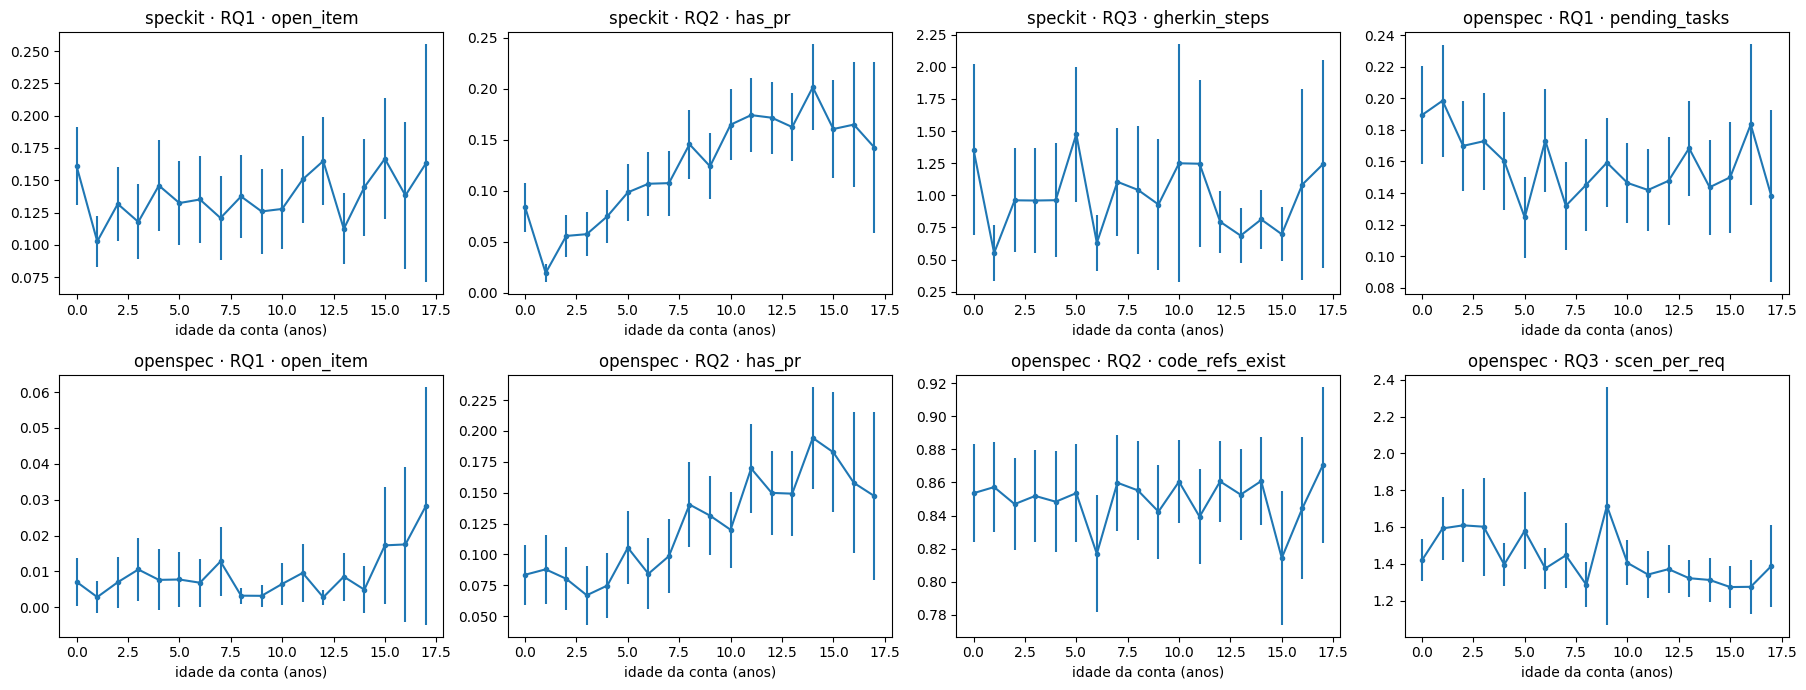

In [25]:
# 7) Gráfico: idade em faixas de 1 ano x média da medida (faixas só para visualizar)
fig, axs = plt.subplots(2, 4, figsize=(18, 7)); axs = axs.ravel(); k = 0
for tool, lista in MEDIDAS.items():
    a = aut[tool].copy()
    a['faixa'] = np.floor(a.idade_anos).clip(upper=17)
    for rq, m in lista:
        g = a.dropna(subset=[m]).groupby('faixa')[m]
        media, n = g.mean(), g.size()
        erro = 1.96 * g.std() / np.sqrt(n)
        axs[k].errorbar(media.index, media.values, yerr=erro.values, fmt='o-', ms=3)
        axs[k].set(title=f'{tool} · {rq} · {m}', xlabel='idade da conta (anos)')
        k += 1
for j in range(k, len(axs)): axs[j].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(DATA, 'dimensoes_x_idade.png'), dpi=200); plt.show()

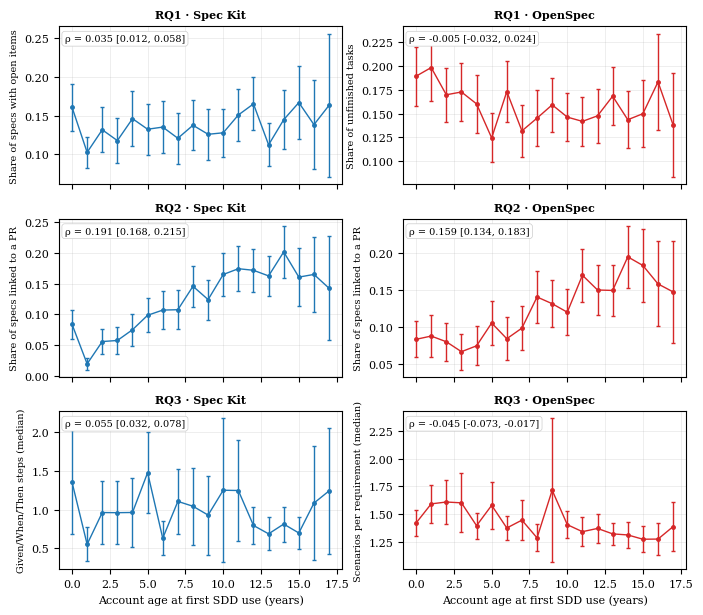

In [27]:
# 10) Figura para o artigo: 6 painéis (3 RQs x 2 ferramentas), em inglês, com rho e IC em cada painel
import matplotlib.pyplot as plt

PAINEIS = [  # (ferramenta, medida, título do painel, rótulo do eixo y)
    ('speckit',  'open_item',     'RQ1 · Spec Kit',  'Share of specs with open items'),
    ('openspec', 'pending_tasks', 'RQ1 · OpenSpec',  'Share of unfinished tasks'),
    ('speckit',  'has_pr',        'RQ2 · Spec Kit',  'Share of specs linked to a PR'),
    ('openspec', 'has_pr',        'RQ2 · OpenSpec',  'Share of specs linked to a PR'),
    ('speckit',  'gherkin_steps', 'RQ3 · Spec Kit',  'Given/When/Then steps (median)'),
    ('openspec', 'scen_per_req',  'RQ3 · OpenSpec',  'Scenarios per requirement (median)'),
]
COR = {'speckit': '#1f77b4', 'openspec': '#d62728'}

plt.rcParams.update({'font.size': 8, 'font.family': 'serif'})
fig, axs = plt.subplots(3, 2, figsize=(7.0, 6.2), sharex=True)   # 7 pol = largura de 2 colunas IEEE
for ax, (tool, m, titulo, ylab) in zip(axs.ravel(), PAINEIS):
    a = aut[tool].dropna(subset=[m]).copy()
    a['faixa'] = np.floor(a.idade_anos).clip(upper=17)
    g = a.groupby('faixa')[m]
    media, erro = g.mean(), 1.96 * g.std() / np.sqrt(g.size())
    ax.errorbar(media.index, media.values, yerr=erro.values, fmt='o-', ms=2.5,
                lw=1, capsize=1.5, color=COR[tool])
    linha = res[(res.ferramenta == tool) & (res.medida == m)].iloc[0]
    ax.text(0.02, 0.95, f"ρ = {linha.rho:.3f} [{linha.ic95_baixo:.3f}, {linha.ic95_alto:.3f}]",
            transform=ax.transAxes, va='top', fontsize=7,
            bbox=dict(boxstyle='round', fc='white', ec='0.8', lw=0.5))
    ax.set_title(titulo, fontsize=8, fontweight='bold')
    ax.set_ylabel(ylab, fontsize=7)
    ax.grid(alpha=0.3, lw=0.5)
for ax in axs[-1]:
    ax.set_xlabel('Account age at first SDD use (years)')
fig.tight_layout()
fig.savefig(os.path.join(DATA, 'fig_resultados.pdf'))            # para o Overleaf
fig.savefig(os.path.join(DATA, 'fig_resultados.png'), dpi=300)   # para o Google Docs
plt.show()